# Decomposing a doubly stochastic matrix

This native Julia companion preserves the finite examples, public data boundary, concentration measures and absolute tolerance. As the original notebook states, stochastic witnesses and permutation decompositions are nonunique: validation checks mapping, reconstruction, positive mixture weights and total mass. It does not require particular witness entries or permutation lists. All calculations run natively in Julia. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

## A Matrix Witness for Majorization

A square matrix $D$ is doubly stochastic when its entries are nonnegative and every row and column sums to one:

$$
D_{ij}\geq0,
\qquad
\sum_{j=1}^{n}D_{ij}=1,
\qquad
\sum_{i=1}^{n}D_{ij}=1.
$$

Here, $D_{ij}$ is the entry in row $i$ and column $j$, and $n$ is the matrix dimension. A target vector $y$ is majorized by a source vector $x$ exactly when there is a doubly stochastic matrix satisfying

$$
y=Dx.
$$

The matrix is a witness to the direction of the relation. It averages and redistributes the source components without changing their total.

Row,Matrix row,Column 1,Column 2,Column 3,Column 4
,String,Float64,Float64,Float64,Float64
1,Row 1,0.51951,0.229419,0.14266,0.108412
2,Row 2,0.297291,0.288685,0.22409,0.189934
3,Row 3,0.137462,0.280918,0.299241,0.282379
4,Row 4,0.0457374,0.200978,0.334009,0.419276


Row,Index,Row sum,Column sum
,Int64,Float64,Float64
1,1,1.0,1.0
2,2,1.0,1.0
3,3,1.0,1.0
4,4,1.0,1.0


Row,Component,Source,Target,D times source,Residual
,Int64,Float64,Float64,Float64,Float64
1,1,0.58,0.38,0.38,-5.55112e-17
2,2,0.24,0.28,0.28,-5.55112e-17
3,3,0.12,0.2,0.2,-8.32667e-17
4,4,0.06,0.14,0.14,0.0


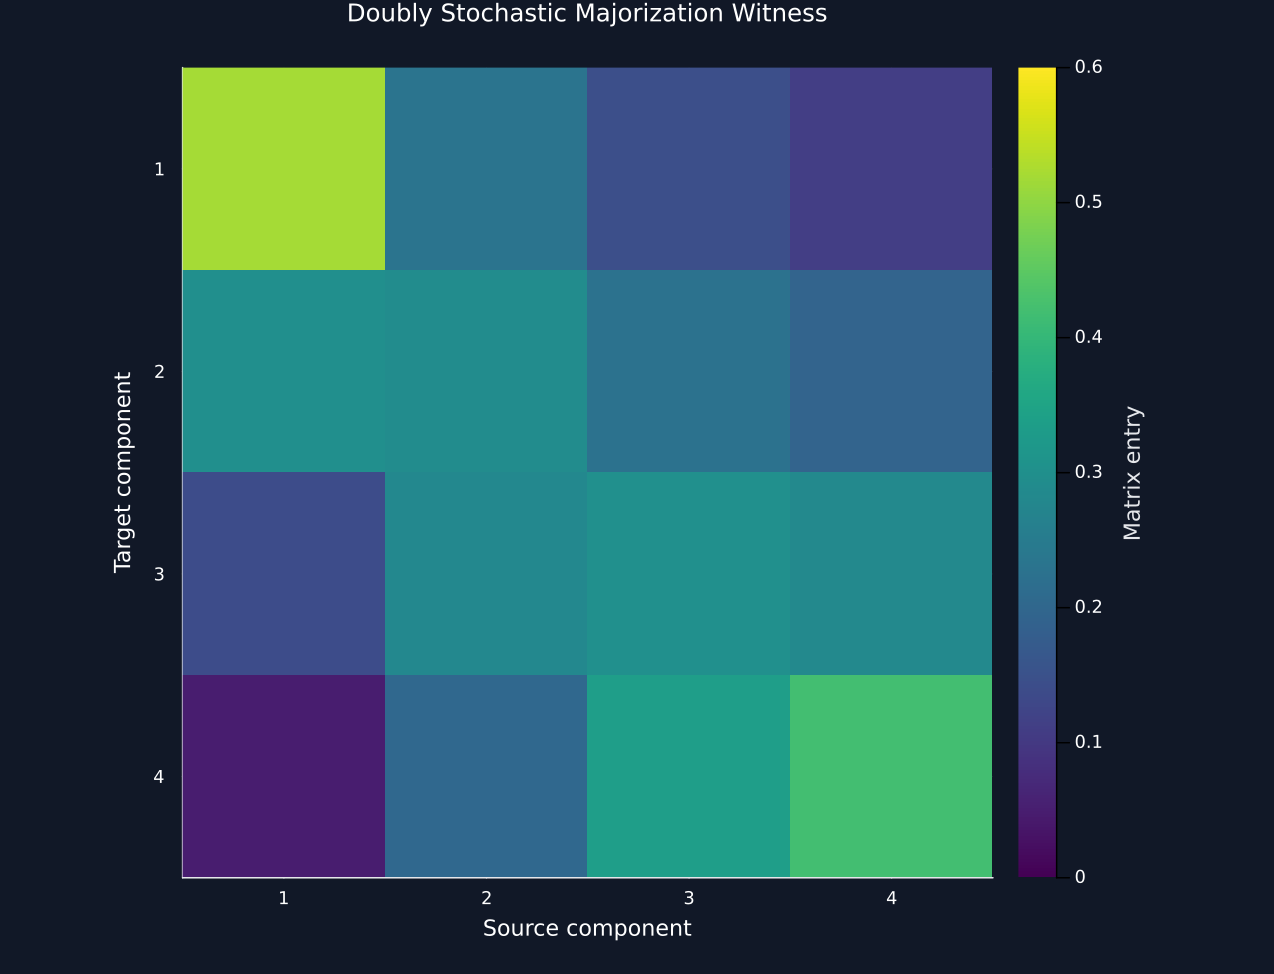

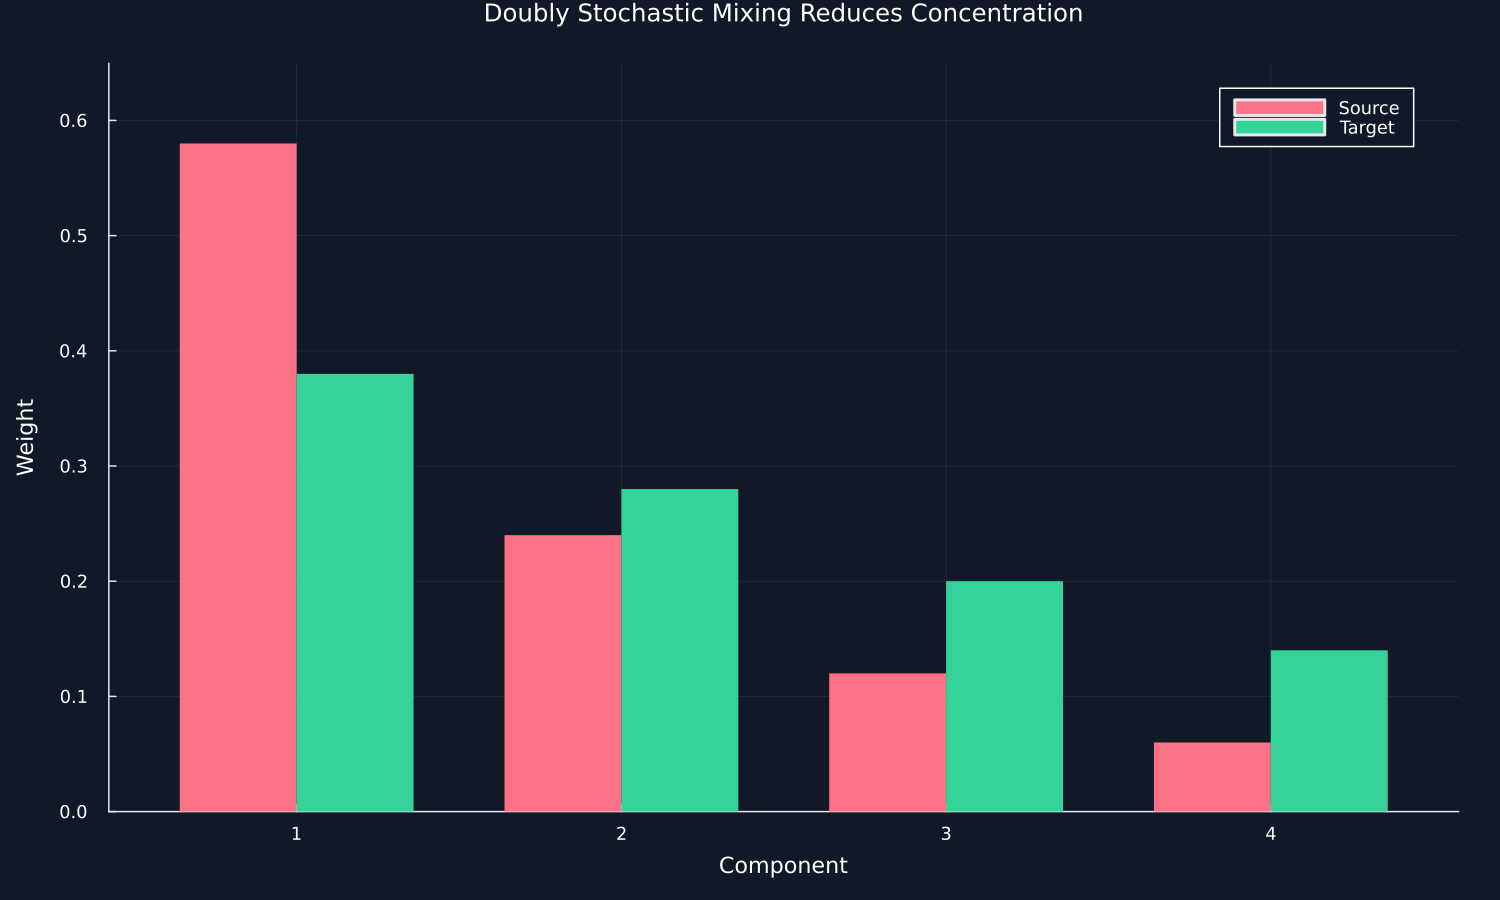

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("24_portfolio_majorization");
using CSV, Printf
using RiskLabAI.Optimization: birkhoff_von_neumann_decomposition,is_doubly_stochastic,is_majorized,majorization_matrix
violet = "#C084FC"
ordered(values) = sort(Float64.(values);rev=true)
partial_sums(values) = cumsum(ordered(values))
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter25-"*replace(name,"_"=>"-"))
function concentration_record(name,values)
    positive = values[values.>0]
    squared = sum(abs2,values)
    entropy = -sum(positive.*log.(positive))
    return (Vector=name,largest=maximum(values),squared=squared,fourth=sum(values.^4),effective=1/squared,entropy_effective=exp(entropy))
end
function concentration_table(vectors)
    frame = DataFrame([concentration_record(name,values) for (name,values) in vectors])
    rename!(frame,["Vector","Largest component","Squared sum","Fourth power sum","Effective count","Entropy effective count"])
    return frame
end
function matrix_table(matrix)
    return hcat(DataFrame("Matrix row"=>["Row "*string(i) for i in axes(matrix,1)]),DataFrame(matrix,["Column "*string(i) for i in axes(matrix,2)]))
end
function matrix_data(matrix)
    return hcat(DataFrame(row=collect(axes(matrix,1))),DataFrame(matrix,["x"*string(i) for i in axes(matrix,2)]))
end
function decomposition_data(weights,orders)
    return hcat(DataFrame(term=collect(eachindex(weights)),weight=weights),DataFrame(orders,["column_"*string(i) for i in axes(orders,2)]))
end
function restore_decomposition(weights,orders)
    identity = Matrix{Float64}(I,size(orders,2),size(orders,2))
    return sum(weight.*identity[orders[index,:],:] for (index,weight) in enumerate(weights))
end
source,target = [0.58,0.24,0.12,0.06],[0.38,0.28,0.20,0.14]
source_before,target_before = copy(source),copy(target)
witness = majorization_matrix(target,source)
mapped = witness*source
table(matrix_table(witness),"stochastic_witness_matrix","A doubly stochastic witness that maps the source to the target.")
sums = DataFrame("Index"=>1:4,"Row sum"=>vec(sum(witness;dims=2)),"Column sum"=>vec(sum(witness;dims=1)))
table(sums,"stochastic_row_column_sums","Row and column sums of the witness matrix.")
mapping = DataFrame("Component"=>1:4,"Source"=>source,"Target"=>target,"D times source"=>mapped,"Residual"=>mapped-target)
table(mapping,"witness_mapping","Numerical check of the witness direction.")
save_data(mapping,paths,"witness_mapping")
save_data(matrix_data(witness),paths,"doubly_stochastic_matrix")
figure = heatmap(1:4,1:4,witness;color=:viridis,clims=(0,max(0.6,maximum(witness))),yflip=true,aspect_ratio=:equal,xticks=1:4,yticks=1:4,xlims=(0.5,4.5),ylims=(0.5,4.5),widen=false,xlabel="Source component",ylabel="Target component",title="Doubly Stochastic Majorization Witness",colorbar_title="Matrix entry",size=(850,650))
save_figure(figure,paths,"doubly_stochastic_matrix")
figure = bar(collect(1:4).-0.18,source;bar_width=0.36,color=palette.rose,linealpha=0,label="Source",xticks=1:4,title="Doubly Stochastic Mixing Reduces Concentration",xlabel="Component",ylabel="Weight",ylims=(0,1.12*maximum(source)),legend=:topright,size=(1000,600))
bar!(figure,collect(1:4).+0.18,target;bar_width=0.36,color=palette.green,linealpha=0,label="Target")
save_figure(figure,paths,"witness_mapping")
@assert size(witness)==(4,4)
@assert maximum(abs,mapped-target)<=1e-10
@assert is_doubly_stochastic(witness)


## A Mixture of Permutations

Every $n\times n$ doubly stochastic matrix can be written as a convex mixture of permutation matrices:

$$
D=\sum_{r=1}^{R}\lambda_r P_r,
\qquad
\lambda_r>0,
\qquad
\sum_{r=1}^{R}\lambda_r=1.
$$

Here, $P_r$ is permutation matrix $r$, $\lambda_r$ is its mixture weight, and $R$ is the number of retained terms. The representation need not be unique. The numerical check must therefore verify reconstruction, positivity, and total weight rather than demand a particular list of permutations.

Row,Matrix row,Column 1,Column 2,Column 3,Column 4
,String,Float64,Float64,Float64,Float64
1,Row 1,0.4,0.35,0.0,0.25
2,Row 2,0.0,0.4,0.6,0.0
3,Row 3,0.0,0.25,0.4,0.35
4,Row 4,0.6,0.0,0.0,0.4


Row,Term,Weight,Selected columns
,Int64,Float64,String
1,1,0.35,2 3 4 1
2,2,0.25,4 3 2 1
3,3,0.4,1 2 3 4


Row,Check,Value,Pass
,String,Float64,Bool
1,Mixture weights sum to one,1.0,true
2,All mixture weights are positive,0.25,true
3,Largest reconstruction residual,0.0,true
4,Input matrix remains unchanged,0.0,true


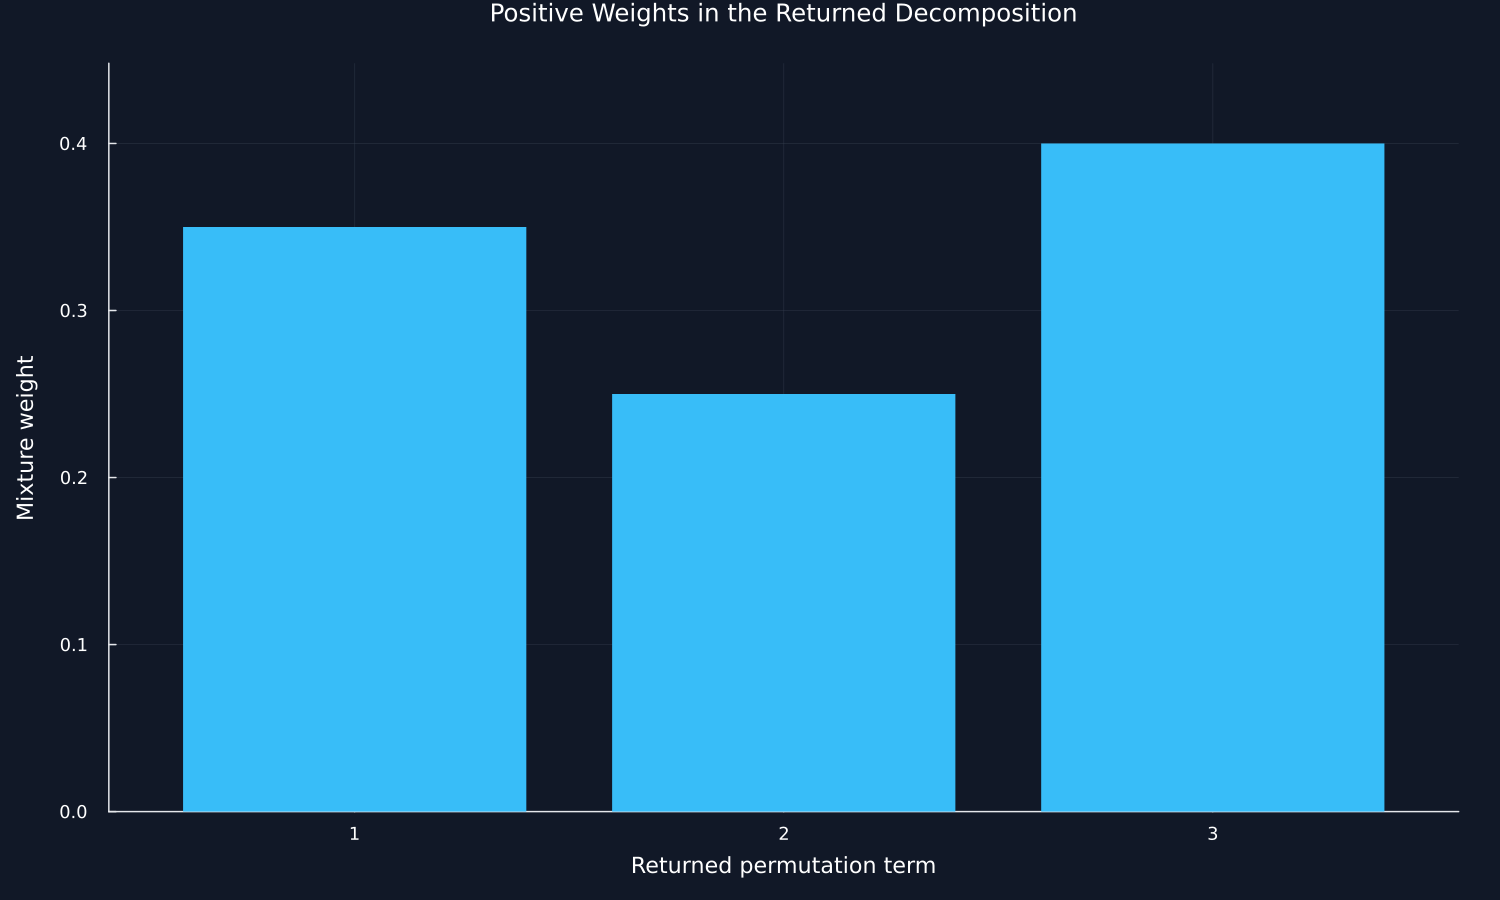

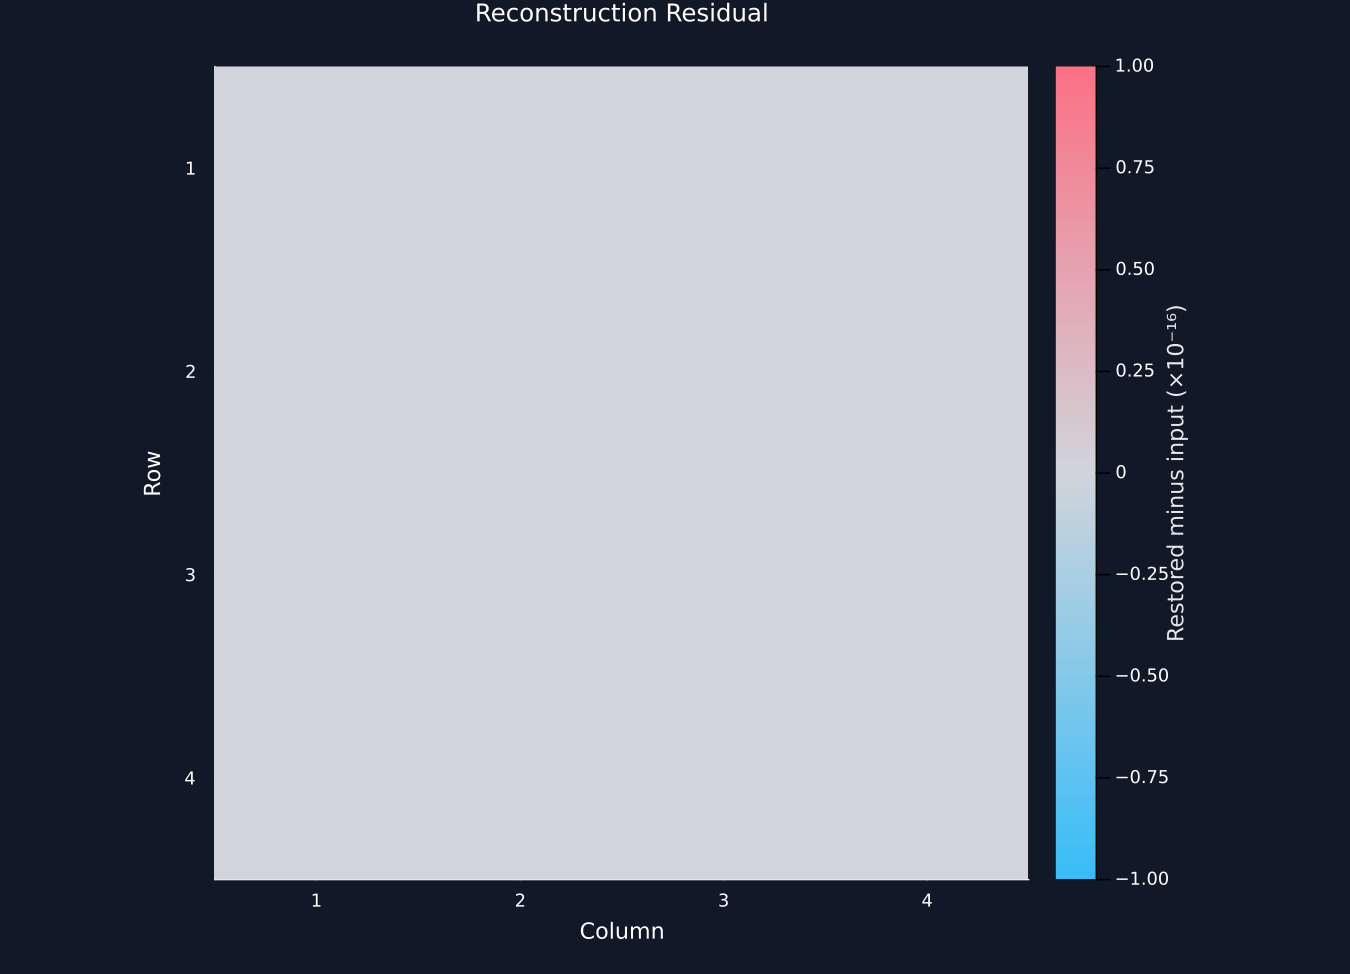

Row,Mixing fraction,Squared concentration,Largest component,Component standard deviation,Target majorized by source
,Float64,Float64,Float64,Float64,Bool
1,0.0,0.412,0.58,0.201246,true
2,0.1,0.385266,0.5551,0.183893,true
3,0.2,0.361824,0.5302,0.167201,true
4,0.3,0.341675,0.5053,0.151389,true
5,0.4,0.324818,0.4804,0.136764,true
6,0.5,0.311252,0.4555,0.123746,true
7,0.6,0.30098,0.4306,0.112893,true
8,0.7,0.293999,0.4057,0.10488,true
9,0.8,0.29031,0.3808,0.100387,true


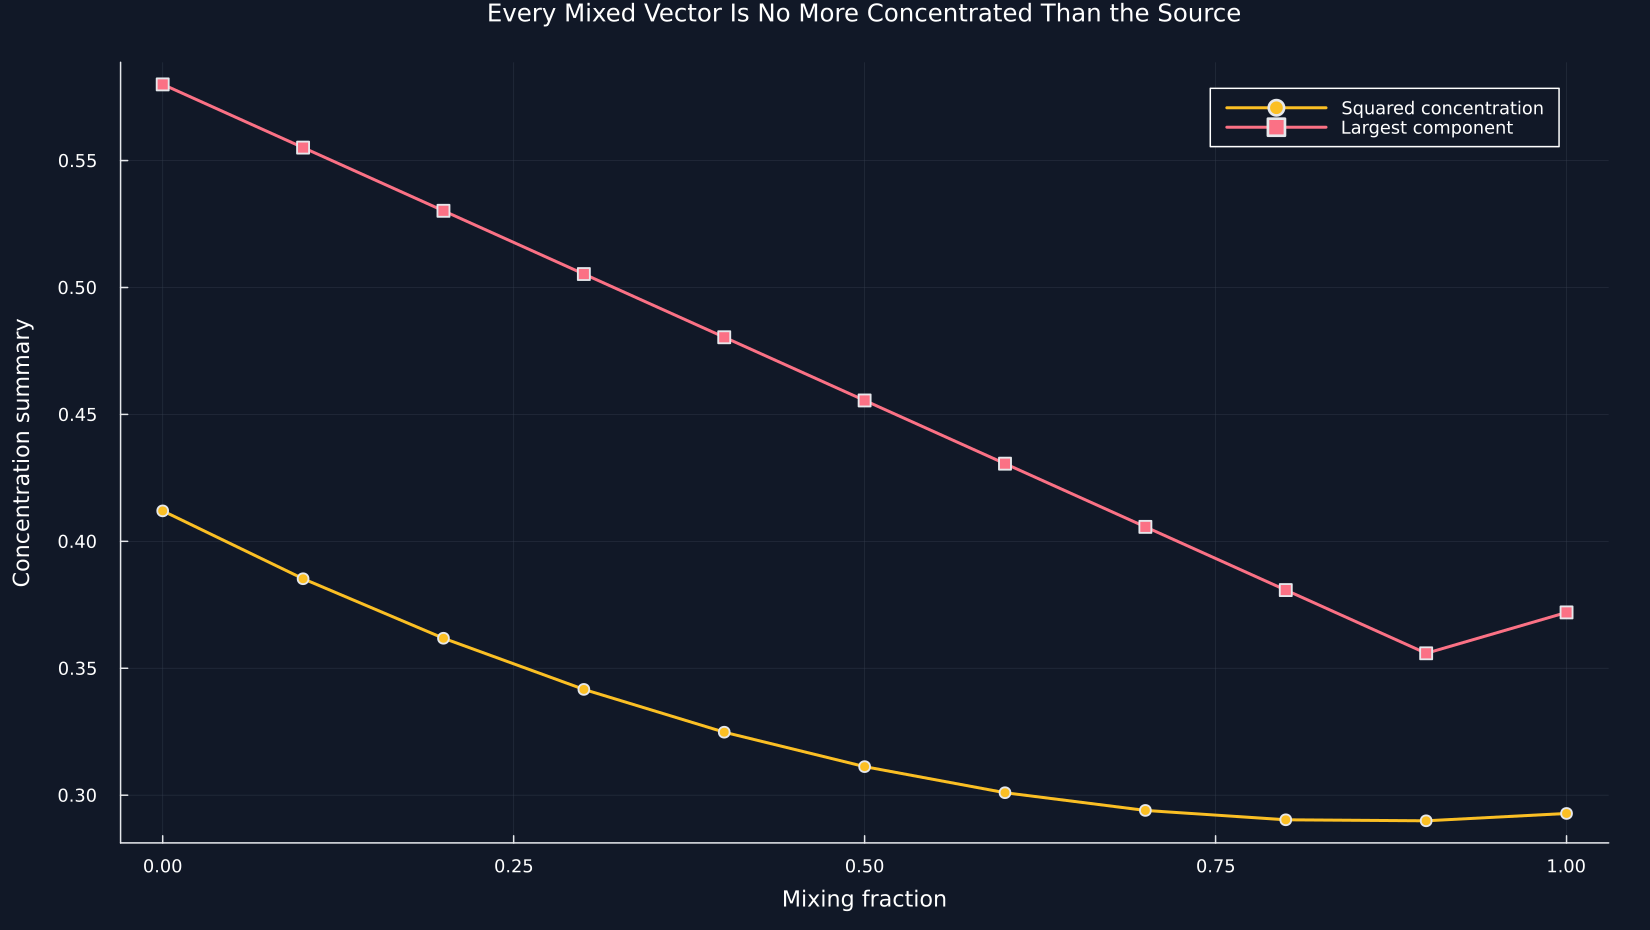

In [2]:
orders_given = [1 2 3 4;2 3 4 1;4 3 2 1]
weights_given = [0.40,0.35,0.25]
mixture = restore_decomposition(weights_given,orders_given)
mixture_before = copy(mixture)
weights_found,orders_found = birkhoff_von_neumann_decomposition(mixture)
restored = restore_decomposition(weights_found,orders_found)
table(matrix_table(mixture),"birkhoff_input_matrix","Doubly stochastic matrix supplied to the decomposition.")
terms = DataFrame("Term"=>collect(eachindex(weights_found)),"Weight"=>weights_found,"Selected columns"=>[join(row," ") for row in eachrow(orders_found)])
table(terms,"birkhoff_terms","Checked Birkhoff decomposition returned by RiskLabAI.")
save_data(terms,paths,"birkhoff_weights")
save_data(decomposition_data(weights_found,orders_found),paths,"birkhoff_decomposition")
residual = restored-mixture
reconstruction = DataFrame("Check"=>["Mixture weights sum to one","All mixture weights are positive","Largest reconstruction residual","Input matrix remains unchanged"],"Value"=>[sum(weights_found),minimum(weights_found),maximum(abs,residual),maximum(abs,mixture-mixture_before)],"Pass"=>[abs(sum(weights_found)-1)<=1e-10,all(weights_found.>0),maximum(abs,residual)<=1e-10,mixture==mixture_before])
table(reconstruction,"birkhoff_reconstruction_checks","Numerical checks for the Birkhoff decomposition.")
save_data(matrix_data(residual),paths,"birkhoff_reconstruction")
figure = bar(terms.Term,terms.Weight;color=palette.cyan,linealpha=0,legend=false,xticks=terms.Term,title="Positive Weights in the Returned Decomposition",xlabel="Returned permutation term",ylabel="Mixture weight",ylims=(0,1.12*maximum(terms.Weight)),size=(1000,600))
save_figure(figure,paths,"birkhoff_weights")
scaled_residual = residual./1e-16
limit = max(1.0,maximum(abs,scaled_residual))
figure = heatmap(1:4,1:4,scaled_residual;color=cgrad([palette.cyan,"#D1D5DB",palette.rose]),clims=(-limit,limit),yflip=true,aspect_ratio=:equal,xticks=1:4,yticks=1:4,xlims=(0.5,4.5),ylims=(0.5,4.5),widen=false,title="Reconstruction Residual",xlabel="Column",ylabel="Row",colorbar_title="Restored minus input (×10⁻¹⁶)",size=(900,650))
save_figure(figure,paths,"birkhoff_reconstruction")
identity = Matrix{Float64}(I,4,4)
alphas = collect(range(0.0,1.0;length=11))
mixing_rows = NamedTuple[]
mixed_values = zeros(11,4)
for (index,alpha) in enumerate(alphas)
    path_matrix = (1-alpha)*identity+alpha*mixture
    mixed = path_matrix*source
    mixed_values[index,:] = mixed
    push!(mixing_rows,(alpha=alpha,squared=sum(abs2,mixed),largest=maximum(mixed),deviation=std(mixed;corrected=false),majorized=is_majorized(mixed,source)))
end
mixing_path = DataFrame(mixing_rows)
rename!(mixing_path,["Mixing fraction","Squared concentration","Largest component","Component standard deviation","Target majorized by source"])
table(mixing_path,"mixture_path_table","Concentration along a convex path of doubly stochastic matrices.")
save_data(mixing_path,paths,"mixture_dispersion_path")
save_data(matrix_data(mixed_values),paths,"mixture_path_weights")
figure = plot(alphas,mixing_path[!,"Squared concentration"];marker=:circle,color=palette.amber,label="Squared concentration",title="Every Mixed Vector Is No More Concentrated Than the Source",xlabel="Mixing fraction",ylabel="Concentration summary",legend=:topright,size=(1100,620))
plot!(figure,alphas,mixing_path[!,"Largest component"];marker=:square,color=palette.rose,label="Largest component")
save_figure(figure,paths,"mixture_dispersion_path")
@assert all(reconstruction.Pass)
@assert all(sort(collect(row))==collect(1:4) for row in eachrow(orders_found))


## Numerical Boundaries

The checks use an absolute tolerance $\varepsilon$. For a computed witness $\widehat D$, the largest mapping residual is

$$
r_{\max}=\max_i\left|\left(\widehat D x\right)_i-y_i\right|.
$$

Here, $x$ is the source, $y$ is the target, and $r_{\max}$ measures the largest componentwise numerical discrepancy. Passing a tolerance check confirms the stated finite calculation. It does not prove that a witness is unique or that a chosen financial allocation is desirable.

In [3]:
signed_source,signed_target = [-2.0,0.0,2.0],[-1.0,0.0,1.0]
signed_witness = majorization_matrix(signed_target,signed_source)
table(matrix_table(signed_witness),"signed_majorization_witness","A checked witness for signed vectors with equal totals.")
save_data(matrix_data(signed_witness),paths,"signed_majorization_witness")
invalid_rows = NamedTuple[]
for (case,candidate) in [("Non-square matrix",[1.0 0.0]),("Unequal column sums",[0.4 0.6;0.4 0.6]),("Material negative entries",[1.1 -0.1;-0.1 1.1])]
    accepted = is_doubly_stochastic(candidate)
    rejected = try
        birkhoff_von_neumann_decomposition(candidate)
        false
    catch exception
        exception isa ArgumentError || rethrow()
        true
    end
    push!(invalid_rows,(Case=case,accepted=accepted,rejected=rejected))
end
invalid_table = DataFrame(invalid_rows)
rename!(invalid_table,["Case","Accepted as doubly stochastic","Decomposition rejects input"])
table(invalid_table,"invalid_matrix_checks","Rejection checks for invalid matrix inputs.")
contract = DataFrame("Check"=>["Target is majorized by source","Witness is doubly stochastic","Witness maps source to target","Source input remains unchanged","Target input remains unchanged","Signed witness maps correctly"],"Pass"=>[is_majorized(target,source),is_doubly_stochastic(witness),maximum(abs,mapped-target)<=1e-10,source==source_before,target==target_before,maximum(abs,signed_witness*signed_source-signed_target)<=1e-10],"Maximum residual"=>[0.0,max(maximum(abs,vec(sum(witness;dims=1)).-1),maximum(abs,vec(sum(witness;dims=2)).-1)),maximum(abs,mapped-target),maximum(abs,source-source_before),maximum(abs,target-target_before),maximum(abs,signed_witness*signed_source-signed_target)])
table(contract,"majorization_contract_checks","Focused numerical checks of the released majorization contract.")
@assert all(contract.Pass)
@assert all(invalid_table[!,"Decomposition rejects input"])
@assert all(mixing_path[!,"Squared concentration"].<=mixing_path[1,"Squared concentration"]+1e-12)
@assert all(mixing_path[!,"Largest component"].<=mixing_path[1,"Largest component"]+1e-12)
@assert all(mixing_path[!,"Target majorized by source"])
@assert !any(invalid_table[!,"Accepted as doubly stochastic"])
@assert isfile(joinpath(paths.figures,"doubly_stochastic_matrix.pdf"))
@assert isfile(joinpath(paths.figures,"witness_mapping.pdf"))
@assert isfile(joinpath(paths.figures,"birkhoff_weights.pdf"))
@assert isfile(joinpath(paths.figures,"birkhoff_reconstruction.pdf"))
@assert isfile(joinpath(paths.figures,"mixture_dispersion_path.pdf"))


Row,Matrix row,Column 1,Column 2,Column 3
,String,Float64,Float64,Float64
1,Row 1,0.598661,0.302678,0.0986609
2,Row 2,0.302678,0.394644,0.302678
3,Row 3,0.0986609,0.302678,0.598661


Row,Case,Accepted as doubly stochastic,Decomposition rejects input
,String,Bool,Bool
1,Non-square matrix,false,true
2,Unequal column sums,false,true
3,Material negative entries,false,true


Row,Check,Pass,Maximum residual
,String,Bool,Float64
1,Target is majorized by source,true,0.0
2,Witness is doubly stochastic,true,2.22045e-16
3,Witness maps source to target,true,8.32667e-17
4,Source input remains unchanged,true,0.0
5,Target input remains unchanged,true,0.0
6,Signed witness maps correctly,true,0.0
